In [1]:
import pandas as pd
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge, SGDRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor, VotingRegressor,BaggingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from scipy.stats import boxcox
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import  train_test_split;
from sklearn.metrics import mean_squared_error, r2_score
import joblib
from math import sqrt

In [2]:
df=pd.read_csv("Cellphone.csv")
df.head(10)

,Product_id,Price,Sale,weight,resoloution,ppi,cpu core,cpu freq,internal mem,ram,RearCam,Front_Cam,battery,thickness
0,203,2357,10,135.0,5.2,424,8,1.35,16.0,3.000,13.00,8.0,2610,7.4
1,880,1749,10,125.0,4.0,233,2,1.30,4.0,1.000,3.15,0.0,1700,9.9
2,40,1916,10,110.0,4.7,312,4,1.20,8.0,1.500,13.00,5.0,2000,7.6
3,99,1315,11,118.5,4.0,233,2,1.30,4.0,0.512,3.15,0.0,1400,11.0
4,880,1749,11,125.0,4.0,233,2,1.30,4.0,1.000,3.15,0.0,1700,9.9
5,947,2137,12,150.0,5.5,401,4,2.30,16.0,2.000,16.00,8.0,2500,9.5
6,774,1238,13,134.1,4.0,233,2,1.20,8.0,1.000,2.00,0.0,1560,11.7
7,947,2137,13,150.0,5.5,401,4,2.30,16.0,2.000,16.00,8.0,2500,9.5
8,99,1315,14,118.5,4.0,233,2,1.30,4.0,0.512,3.15,0.0,1400,11.0
9,1103,2580,15,145.0,5.1,432,4,2.50,16.0,2.000,16.00,2.0,2800,8.1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 161 entries, 0 to 160
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Product_id    161 non-null    int64  
 1   Price         161 non-null    int64  
 2   Sale          161 non-null    int64  
 3   weight        161 non-null    float64
 4   resoloution   161 non-null    float64
 5   ppi           161 non-null    int64  
 6   cpu core      161 non-null    int64  
 7   cpu freq      161 non-null    float64
 8   internal mem  161 non-null    float64
 9   ram           161 non-null    float64
 10  RearCam       161 non-null    float64
 11  Front_Cam     161 non-null    float64
 12  battery       161 non-null    int64  
 13  thickness     161 non-null    float64
dtypes: float64(8), int64(6)
memory usage: 17.7 KB


In [4]:
df.describe()

,Product_id,Price,Sale,weight,resoloution,ppi,cpu core,cpu freq,internal mem,ram,RearCam,Front_Cam,battery,thickness
count,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000
mean,675.559006,2215.596273,621.465839,170.426087,5.209938,335.055901,4.857143,1.502832,24.501714,2.204994,10.378261,4.503106,2842.111801,8.921739
std,410.851583,768.187171,1546.618517,92.888612,1.509953,134.826659,2.444016,0.599783,28.804773,1.609831,6.181585,4.342053,1366.990838,2.192564
min,10.000000,614.000000,10.000000,66.000000,1.400000,121.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,800.000000,5.100000
25%,237.000000,1734.000000,37.000000,134.100000,4.800000,233.000000,4.000000,1.200000,8.000000,1.000000,5.000000,0.000000,2040.000000,7.600000
50%,774.000000,2258.000000,106.000000,153.000000,5.150000,294.000000,4.000000,1.400000,16.000000,2.000000,12.000000,5.000000,2800.000000,8.400000
75%,1026.000000,2744.000000,382.000000,170.000000,5.500000,428.000000,8.000000,1.875000,32.000000,3.000000,16.000000,8.000000,3240.000000,9.800000
max,1339.000000,4361.000000,9807.000000,753.000000,12.200000,806.000000,8.000000,2.700000,128.000000,6.000000,23.000000,20.000000,9500.000000,18.500000


In [5]:
df.isnull().sum()

Product_id      0
Price           0
Sale            0
weight          0
resoloution     0
ppi             0
cpu core        0
cpu freq        0
internal mem    0
ram             0
RearCam         0
Front_Cam       0
battery         0
thickness       0
dtype: int64

In [6]:
df.isna().sum()

Product_id      0
Price           0
Sale            0
weight          0
resoloution     0
ppi             0
cpu core        0
cpu freq        0
internal mem    0
ram             0
RearCam         0
Front_Cam       0
battery         0
thickness       0
dtype: int64

In [7]:
df.drop(columns=["Product_id"],inplace=True)

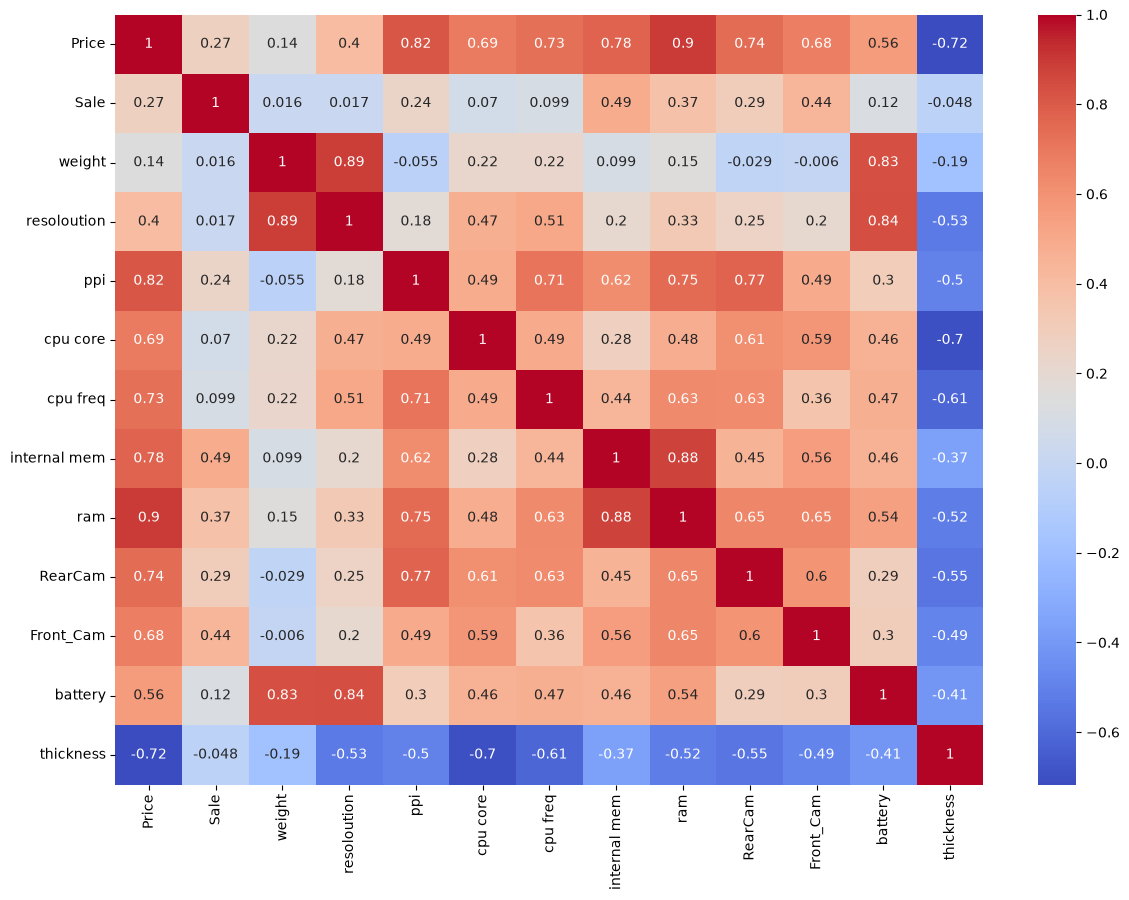

In [8]:
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.show()

In [9]:
# there is no correlation between thickness and price. also sale is not a correct variable for price prediction as price of can be higher or lower 
# and it not dependent on the how much sale in real so i am dropping these two.


In [10]:
df.drop(columns=["Sale","thickness"],inplace=True)

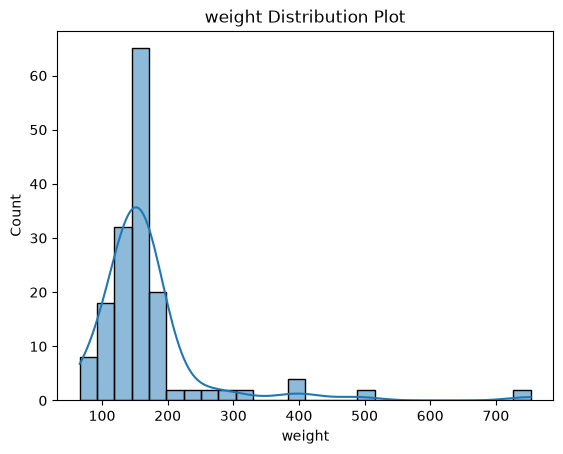

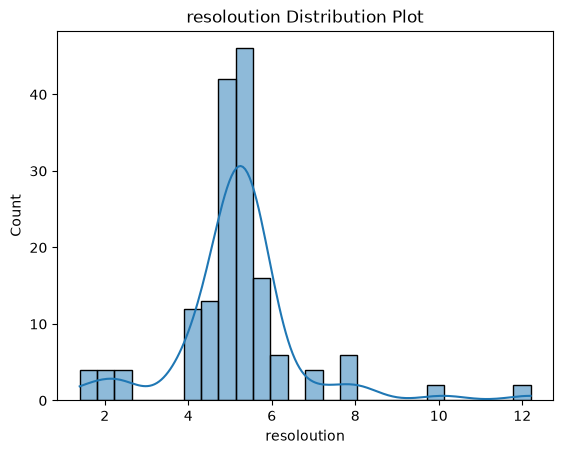

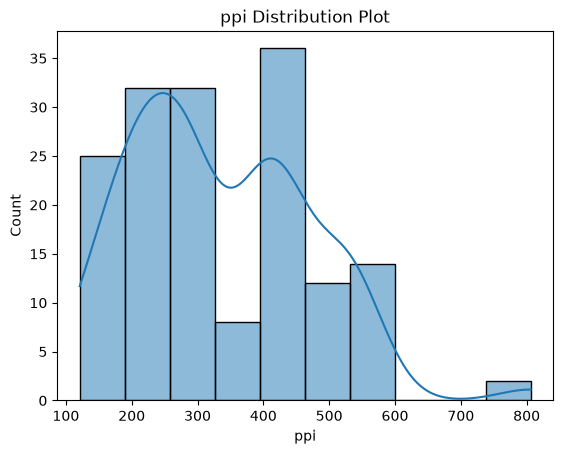

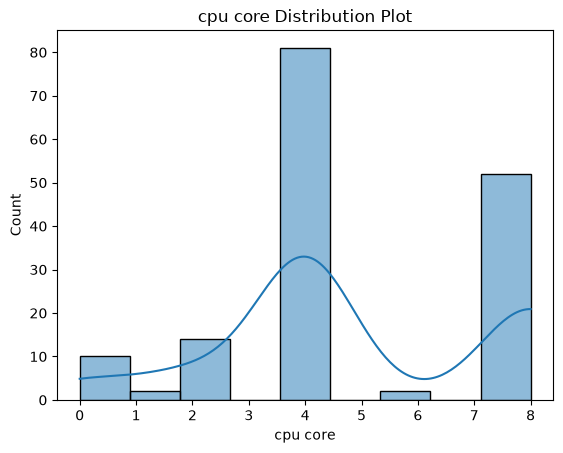

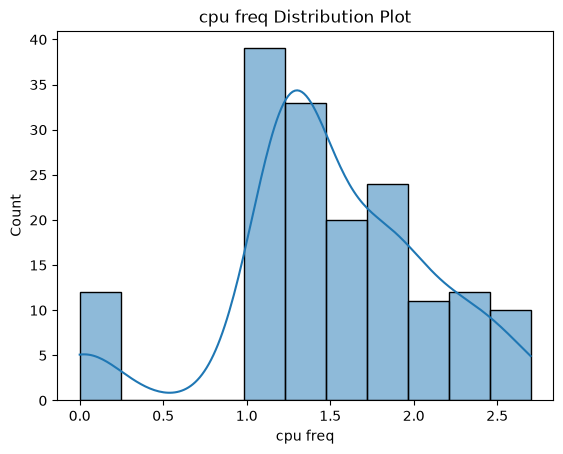

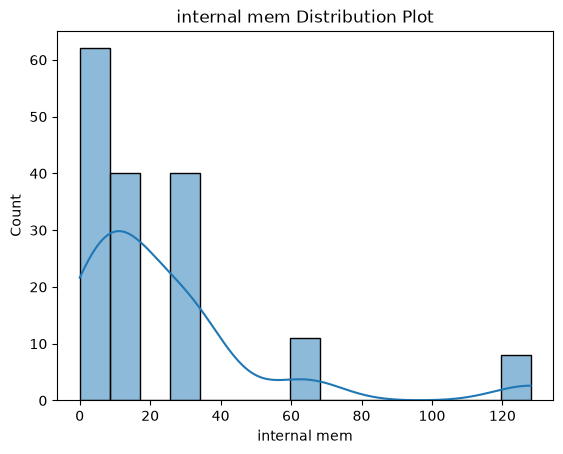

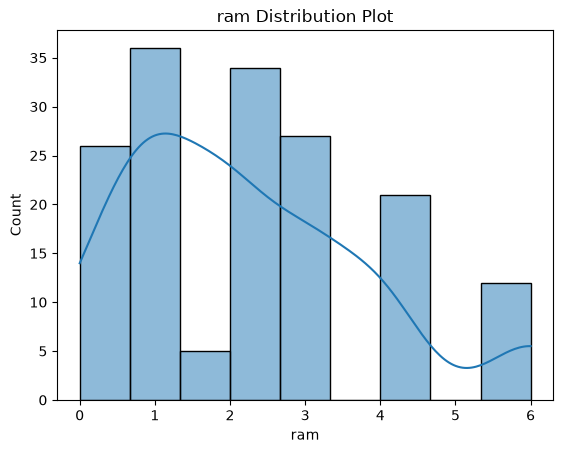

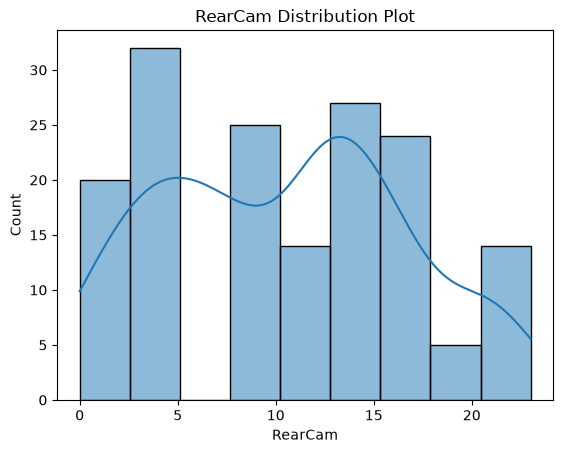

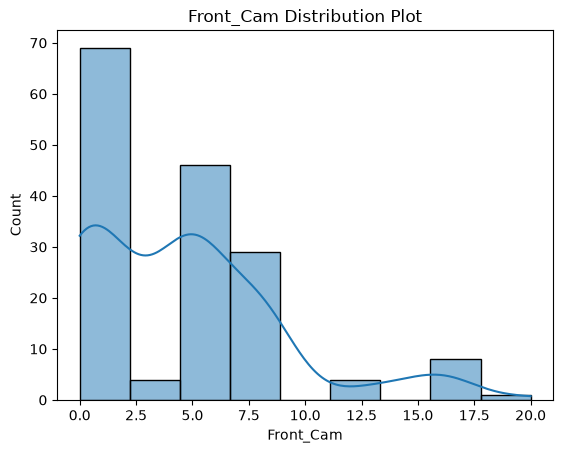

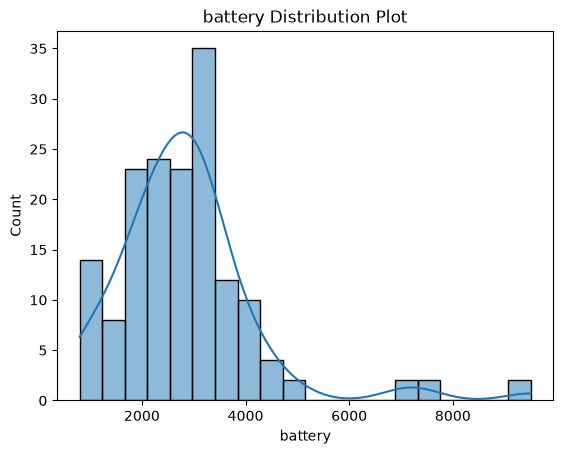

In [11]:
df_data_distribution = df.drop(columns="Price")
columns = df_data_distribution.columns

for column in columns:
    sns.histplot(data=df_data_distribution, x=column, kde=True)
    plt.title(f"{column} Distribution Plot")
    plt.show()

In [12]:
#from here i can see that some variables having skewness.

In [13]:
df.skew()

Price           0.052347
weight          3.981756
resoloution     1.176110
ppi             0.602503
cpu core       -0.009077
cpu freq       -0.512663
internal mem    2.389683
ram             0.792698
RearCam         0.106929
Front_Cam       1.169750
battery         2.092660
dtype: float64

In [14]:
#from here i can see
#Weight is having high skewed
#Resolution is highly skewed
#ppi is moderately skewed
#cpu frequency is moderately skewed
#internal mem is hughly skewed
#ram is moderately skewed
#Front_Cam is highly skewed
#battery is highly skewed
# processing these variables using boxcox function

In [15]:
boxcox_lambdas = {};
transform_columns = ["weight","resoloution","ppi","cpu freq","internal mem","ram","Front_Cam","battery"]
for column in transform_columns:
    transformed_values, fitted_lambdas =  boxcox(df[column] + 1);
    df[column] = transformed_values;
    boxcox_lambdas[column] = fitted_lambdas;

joblib.dump(boxcox_lambdas, "boxcox_lambdas.pkl")



['boxcox_lambdas.pkl']

In [16]:
#after tranformation i will check ahain the skewness
df.skew()

Price           0.052347
weight         -0.165116
resoloution     0.194987
ppi            -0.028039
cpu core       -0.009077
cpu freq        0.014312
internal mem   -0.007992
ram            -0.021790
RearCam         0.106929
Front_Cam      -0.076752
battery         0.034020
dtype: float64

In [17]:
df

,Price,weight,resoloution,ppi,cpu core,cpu freq,internal mem,ram,RearCam,Front_Cam,battery
0,2357,1.612010,3.250736,15.880774,8,1.766973,3.698894,1.575662,13.00,2.809969,17.647307
1,1749,1.607607,2.665984,12.886427,2,1.688427,1.867646,0.738490,3.15,0.000000,15.899819
2,1916,1.599851,3.013414,14.283506,4,1.534070,2.696836,0.996628,13.00,2.186685,16.546081
3,1315,1.604436,2.665984,12.886427,2,1.688427,1.867646,0.429290,3.15,0.000000,15.152679
4,1749,1.607607,2.665984,12.886427,2,1.688427,1.867646,0.738490,3.15,0.000000,15.899819
...,...,...,...,...,...,...,...,...,...,...,...
156,3551,1.626317,3.370975,17.219593,4,2.644458,7.779948,2.332500,12.00,3.904178,19.620992
157,3211,1.624093,3.389293,17.176258,4,2.822092,7.779948,2.332500,20.00,2.809969,18.795884
158,3260,1.617732,3.389293,15.579975,8,3.233488,6.229707,1.868293,20.00,4.302195,18.245252
159,3211,1.624093,3.389293,17.176258,4,2.822092,7.779948,2.332500,20.00,2.809969,18.795884


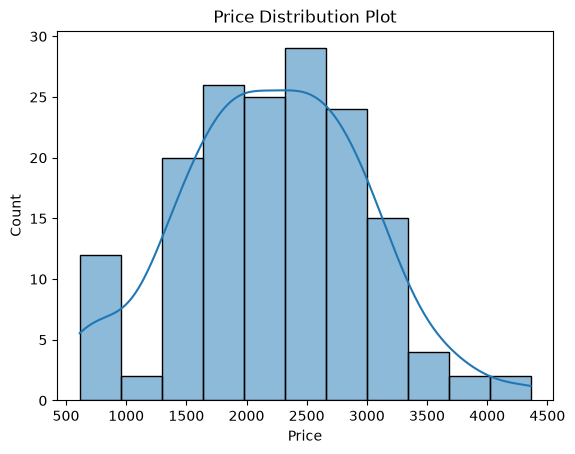

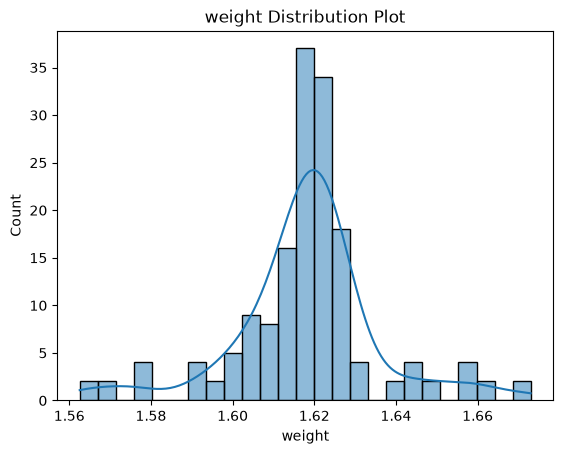

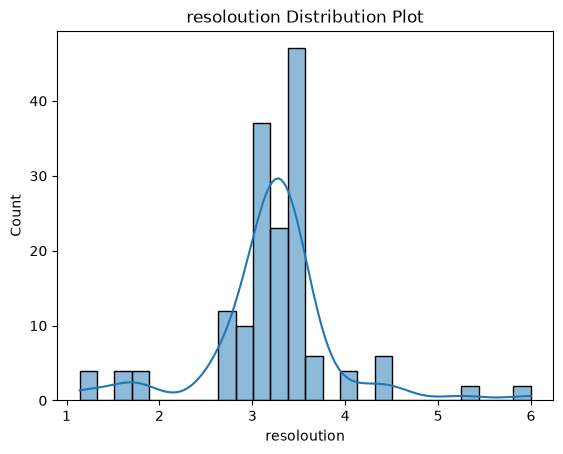

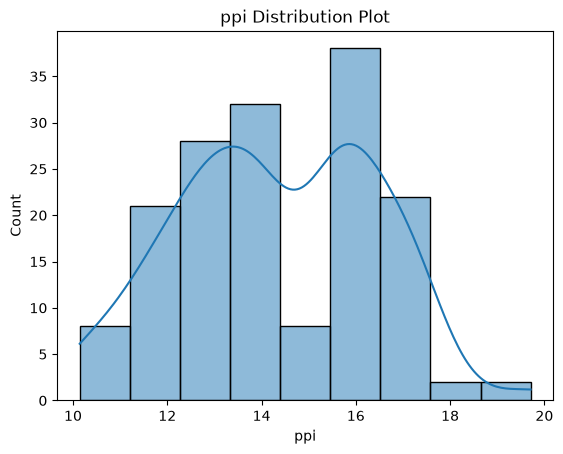

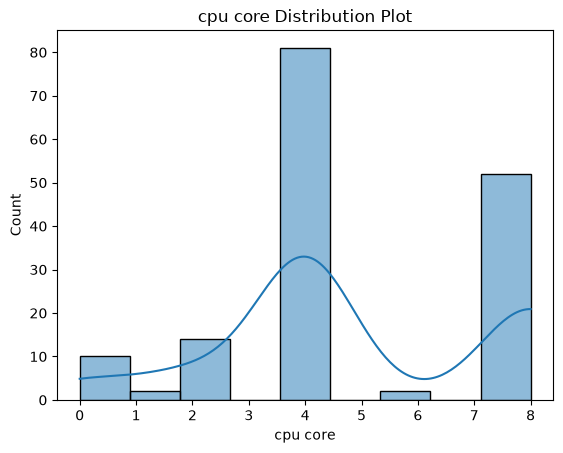

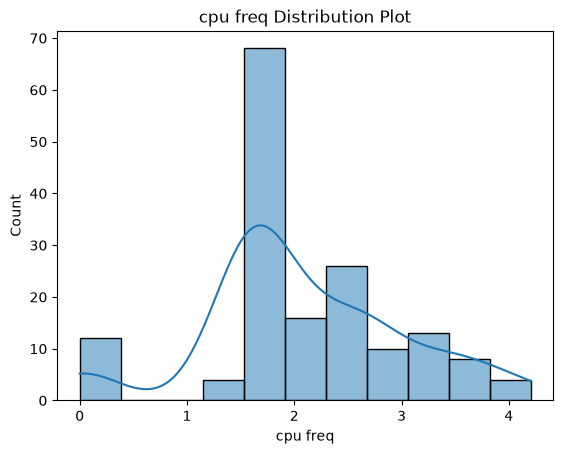

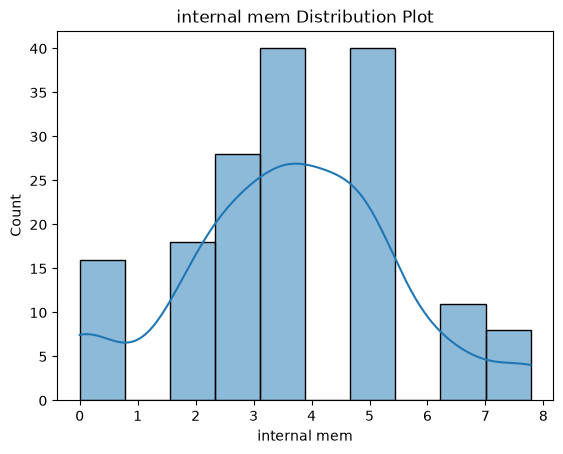

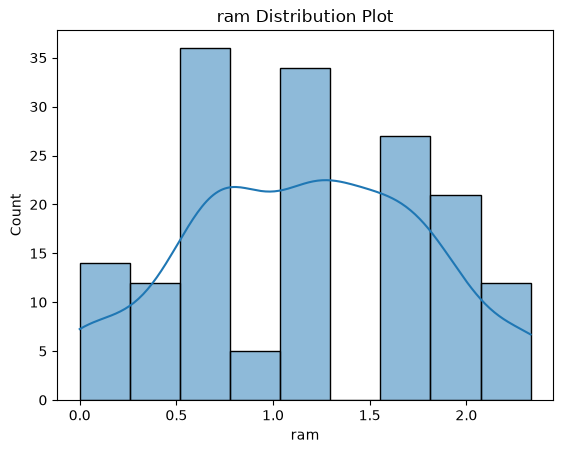

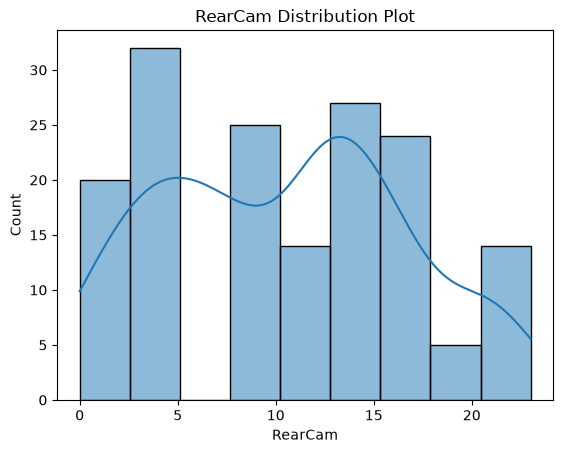

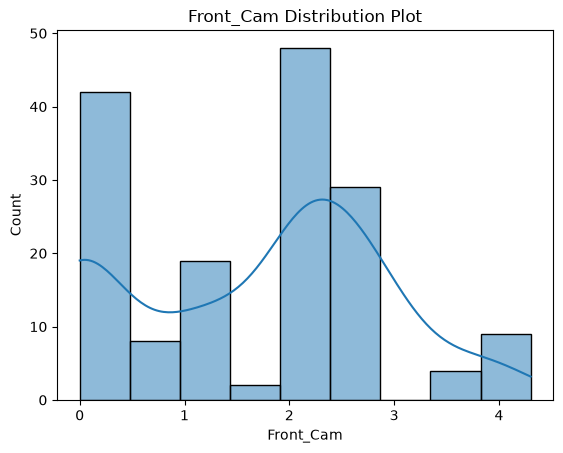

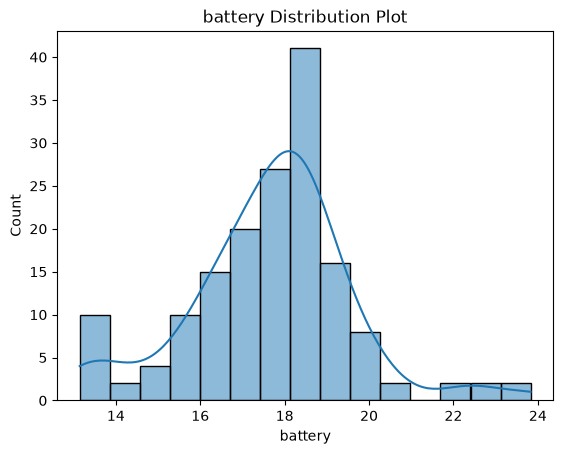

In [18]:
#Rechecking the ditribution of variables
for column in df.columns:
    sns.histplot(data=df, x=column, kde=True)
    plt.title(f"{column} Distribution Plot")
    plt.show()

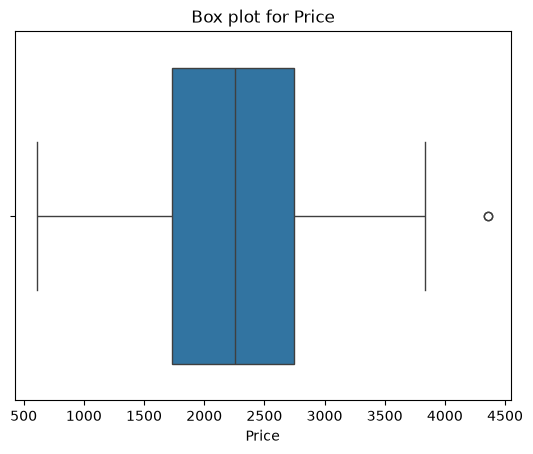

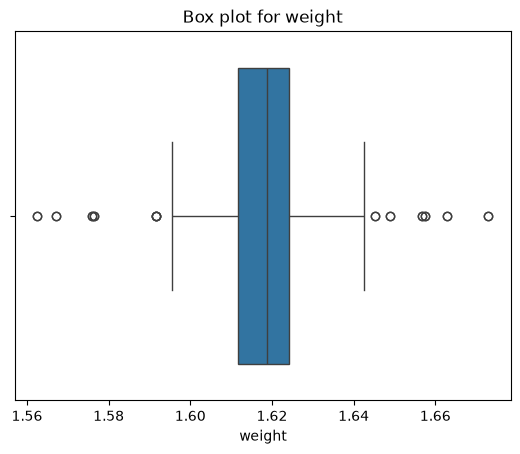

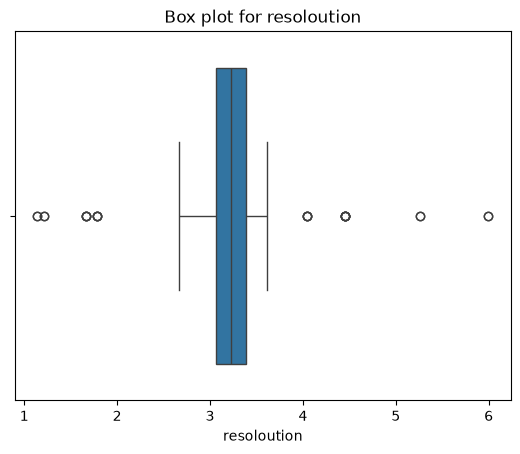

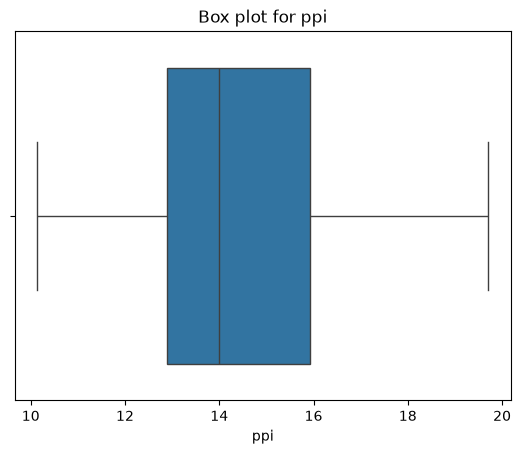

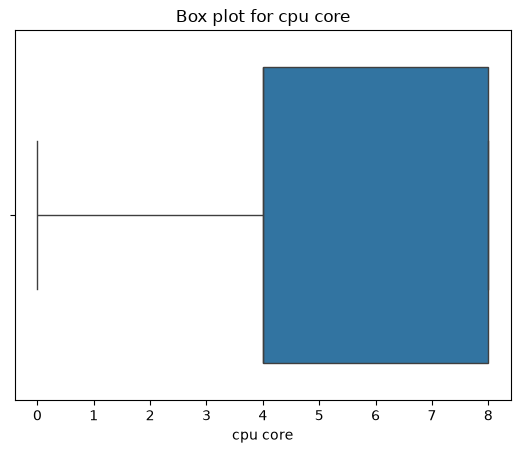

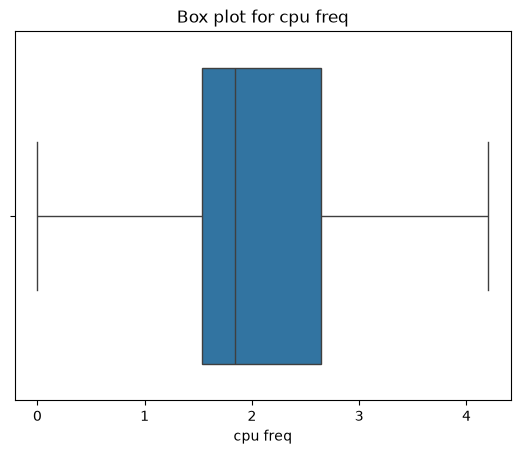

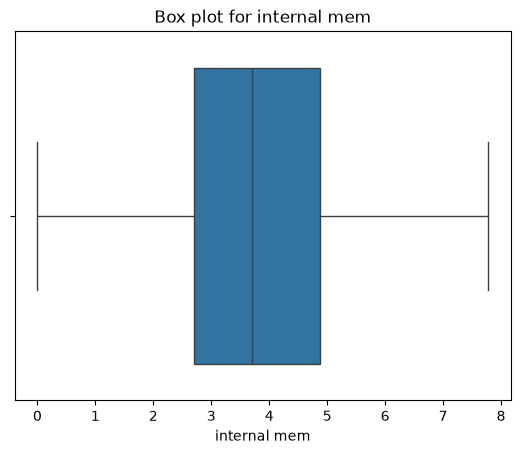

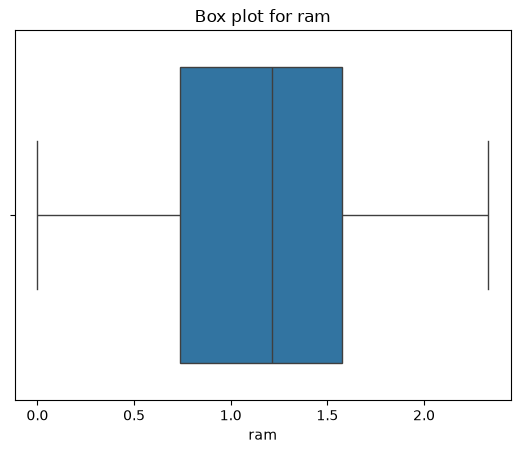

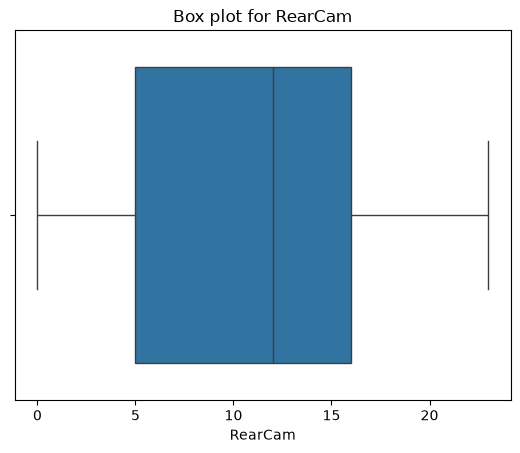

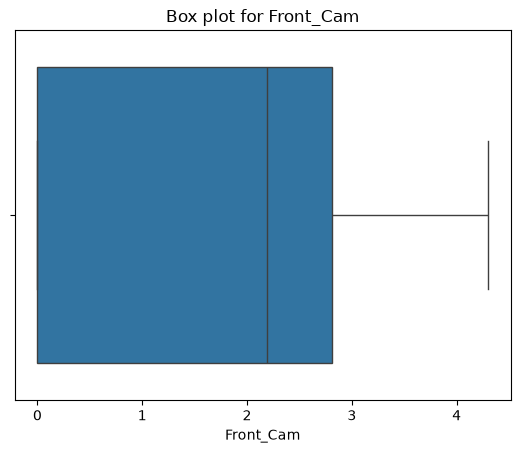

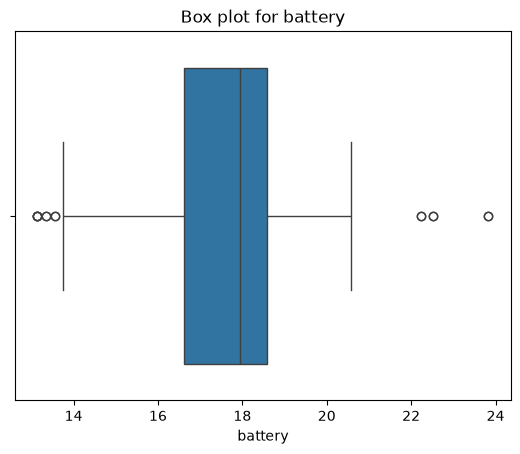

In [19]:
# checking the outliers using boxplot visualization
for column in df.columns:
    sns.boxplot(data=df[column], orient="h")
    plt.title(f"Box plot for {column}")
    plt.show()

In [20]:
#these are outliers in the weight, resolution, battery variables
outliers_columns = ["weight","resoloution","battery"]

for column in outliers_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bond = Q1 - 1.5 * IQR
    upper_bond = Q3 + 1.5 * IQR

    df = df[(df[column]>=lower_bond) & (df[column]<=upper_bond)]
    print(df)
    print("===========================")

     Price    weight  resoloution        ppi  cpu core  cpu freq  \
0     2357  1.612010     3.250736  15.880774         8  1.766973   
1     1749  1.607607     2.665984  12.886427         2  1.688427   
2     1916  1.599851     3.013414  14.283506         4  1.534070   
3     1315  1.604436     2.665984  12.886427         2  1.688427   
4     1749  1.607607     2.665984  12.886427         2  1.688427   
..     ...       ...          ...        ...       ...       ...   
156   3551  1.626317     3.370975  17.219593         4  2.644458   
157   3211  1.624093     3.389293  17.176258         4  2.822092   
158   3260  1.617732     3.389293  15.579975         8  3.233488   
159   3211  1.624093     3.389293  17.176258         4  2.822092   
160   2536  1.632140     3.614417  15.111744         8  2.007975   

     internal mem       ram  RearCam  Front_Cam    battery  
0        3.698894  1.575662    13.00   2.809969  17.647307  
1        1.867646  0.738490     3.15   0.000000  15.899819  


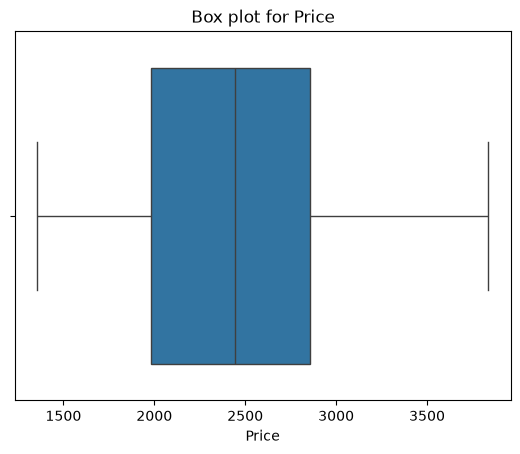

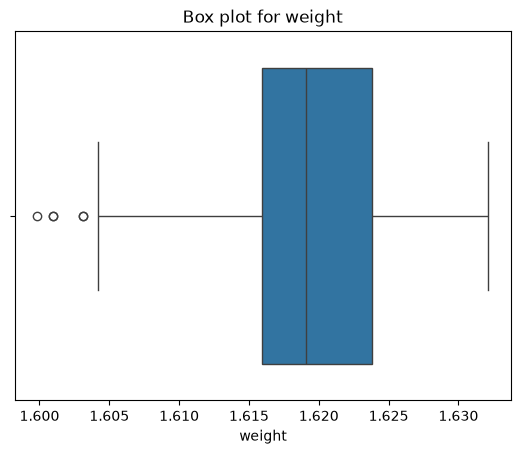

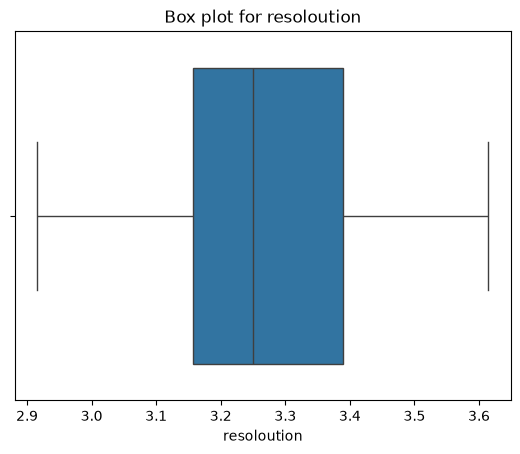

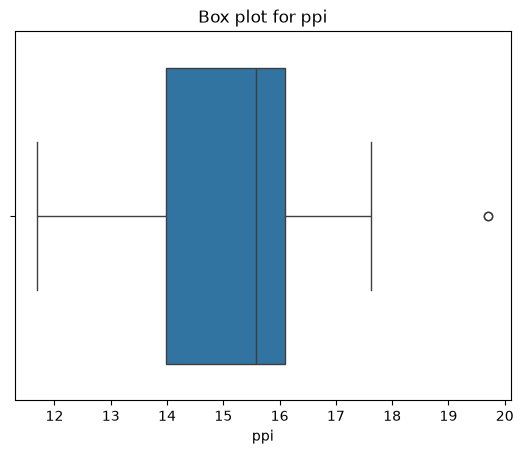

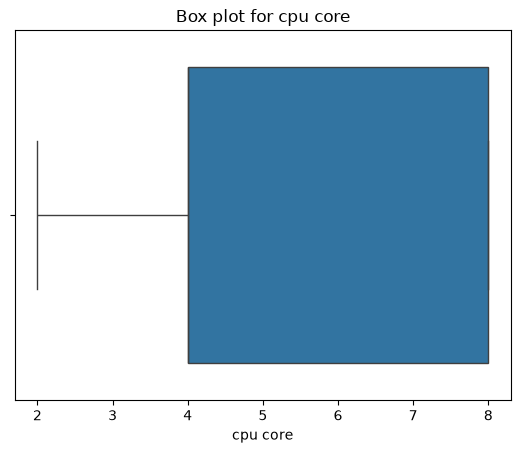

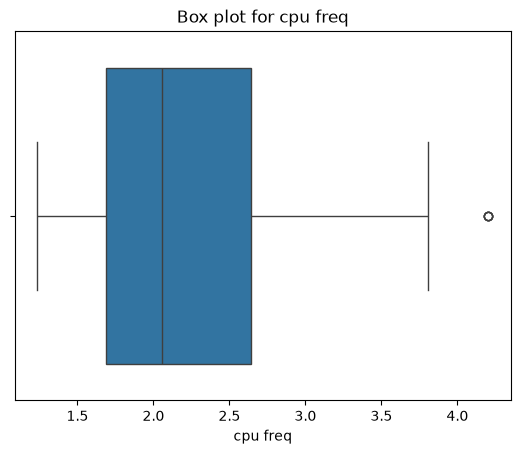

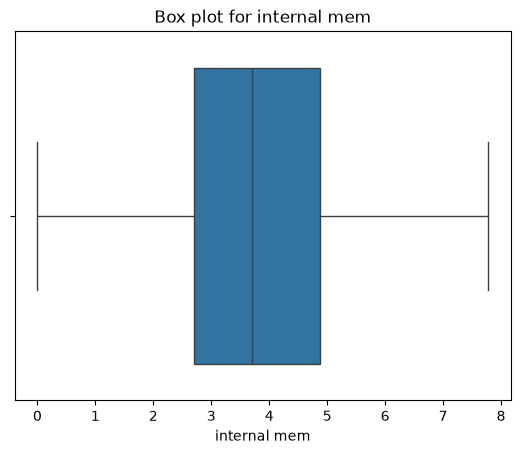

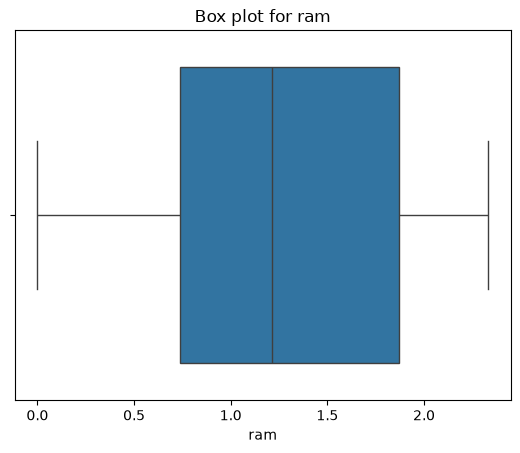

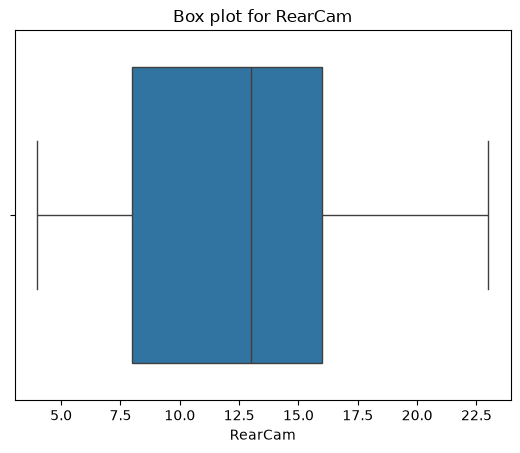

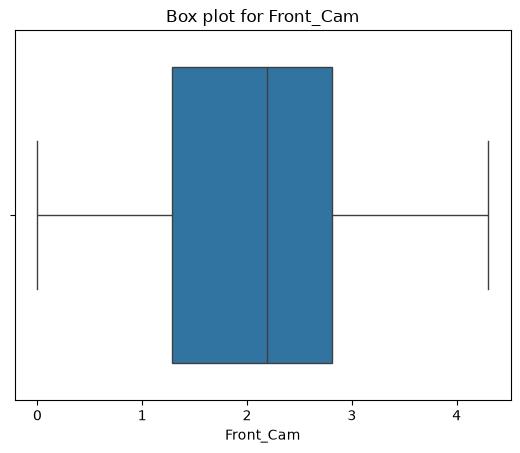

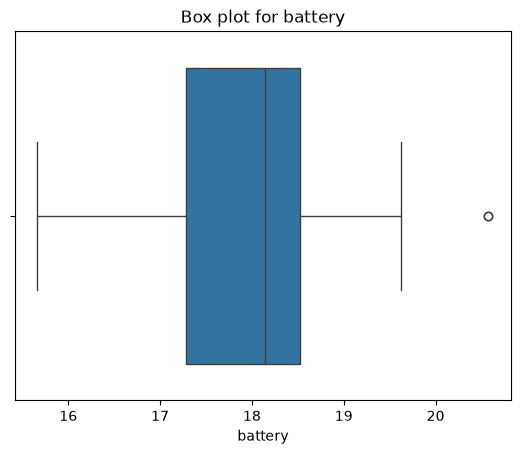

In [21]:
#rechecking for outliers
for column in df.columns:
    sns.boxplot(data=df[column], orient="h")
    plt.title(f"Box plot for {column}")
    plt.show()

In [22]:
# Doing Feature Scaling using standard Scalar

In [23]:
df = df.reset_index(drop=True)
x_data = df.drop(columns="Price")
standard_scalar = StandardScaler()
x_data =standard_scalar.fit_transform(x_data)
x_data

array([[-1.14808753, -0.14743499,  0.46727829, ...,  0.01637432,
         0.6947097 , -0.29906609],
       [-3.05594652, -1.51041366, -0.45606004, ...,  0.01637432,
         0.12920836, -1.41084466],
       [-0.25042667,  0.64831857,  0.29339426, ...,  0.61506046,
         0.6947097 , -0.48261272],
       ...,
       [-0.25042667,  0.64831857,  0.29339426, ...,  1.41330866,
         2.04859541,  0.30460869],
       [ 0.74763854,  0.64831857,  1.21616343, ...,  1.41330866,
         0.6947097 ,  0.86051788],
       [ 2.01015698,  1.94124576,  0.02272252, ...,  1.71265173,
         1.68747765, -0.15353001]], shape=(117, 10))

In [24]:
x_scaled_data =pd.DataFrame(x_data, columns=df.drop(columns="Price").columns);
y_data = df['Price']

In [25]:
x_train,x_test,y_train,y_test = train_test_split(x_scaled_data,y_data,test_size=0.2,random_state=42)

In [26]:
model = ["LinearRegression","Ridge","Lasso","ElasticNet","Decision tree","Random forest","KNN","SVM","Voting Regressor","Adaboost","Gradient Boost"]
r2_score_train =[]
r2_score_test =[]

mse_train = []
mse_test = []

rmse_train = []
rmse_test = []

In [27]:
def model_evaluation(model, x_train, y_train, x_test, y_test):
    model.fit(x_train, y_train)
    y_pred_train = model.predict(x_train)
    y_pred_test = model.predict(x_test)

    r2_train = r2_score(y_train, y_pred_train)
    r2_test = r2_score(y_test, y_pred_test)

    mse_train_value = mean_squared_error(y_train, y_pred_train)
    mse_test_value = mean_squared_error(y_test, y_pred_test)

    rmse_train_value = sqrt(mse_train_value)
    rmse_test_value = sqrt(mse_test_value)

    r2_score_train.append(r2_train)
    r2_score_test.append(r2_test)
    mse_train.append(mse_train_value)
    mse_test.append(mse_test_value)
    rmse_train.append(rmse_train_value)
    rmse_test.append(rmse_test_value)

    print(f"Model: {model.__class__.__name__}")
    print(f"R2 Score (Train): {r2_train}")
    print(f"R2 Score (Test): {r2_test}")
    print(f"MSE (Train): {mse_train_value}")
    print(f"MSE (Test): {mse_test_value}")
    print(f"RMSE (Train): {rmse_train_value}")
    print(f"RMSE (Test): {rmse_test_value}")

    

In [28]:
#Linear Regression
model_evaluation(
  LinearRegression(),
  x_train,  
  y_train,
  x_test,
  y_test
)

Model: LinearRegression
R2 Score (Train): 0.879400099697525
R2 Score (Test): 0.8296261442776984
MSE (Train): 41686.01834399737
MSE (Test): 56834.91041304631
RMSE (Train): 204.17154146451793
RMSE (Test): 238.40073492555828


In [29]:
#Ridge
model_evaluation(
  Ridge(),
  x_train,  
  y_train,
  x_test,
  y_test
)

Model: Ridge
R2 Score (Train): 0.8793383594829524
R2 Score (Test): 0.8309466323920545
MSE (Train): 41707.35918848214
MSE (Test): 56394.40958994322
RMSE (Train): 204.22379682221694
RMSE (Test): 237.47507151266052


In [30]:
#Lasso
model_evaluation(
  Lasso(),
  x_train,  
  y_train,
  x_test,
  y_test
)

Model: Lasso
R2 Score (Train): 0.8793150488980325
R2 Score (Test): 0.8303449755321171
MSE (Train): 41715.41662027224
MSE (Test): 56595.11593417057
RMSE (Train): 204.2435228355412
RMSE (Test): 237.89728021600115


In [31]:
#Elastic net
model_evaluation(
  ElasticNet(),
  x_train,  
  y_train,
  x_test,
  y_test  
)

Model: ElasticNet
R2 Score (Train): 0.8553428348520294
R2 Score (Test): 0.8136514178084683
MSE (Train): 50001.544154056006
MSE (Test): 62163.90965358395
RMSE (Train): 223.61025055675782
RMSE (Test): 249.32691321552903


In [32]:
# decision tree 
model_evaluation(
  DecisionTreeRegressor(),
  x_train,  
  y_train,
  x_test,
  y_test  
)

Model: DecisionTreeRegressor
R2 Score (Train): 1.0
R2 Score (Test): 0.9840811033657645
MSE (Train): 0.0
MSE (Test): 5310.375
RMSE (Train): 0.0
RMSE (Test): 72.87231984779955


In [33]:
#RandomForest
model_evaluation(
  RandomForestRegressor(),
  x_train,  
  y_train,
  x_test,
  y_test  
)

Model: RandomForestRegressor
R2 Score (Train): 0.9880154567946351
R2 Score (Test): 0.9575395255835976
MSE (Train): 4142.523224731186
MSE (Test): 14164.363712500002
RMSE (Train): 64.36243644185004
RMSE (Test): 119.014132406618


In [34]:
#KNN
model_evaluation(
  KNeighborsRegressor(),
  x_train,  
  y_train,
  x_test,
  y_test  
)

Model: KNeighborsRegressor
R2 Score (Train): 0.9061802000909839
R2 Score (Test): 0.8554329715723372
MSE (Train): 32429.329462365593
MSE (Test): 48226.02666666667
RMSE (Train): 180.0814522996902
RMSE (Test): 219.6042501106631


In [35]:
#SVM
model_evaluation(
  SVR(),
  x_train,  
  y_train,
  x_test,
  y_test  
)

Model: SVR
R2 Score (Train): 0.032612116918164125
R2 Score (Test): 0.009014690714491014
MSE (Train): 334382.93844992993
MSE (Test): 330582.1837224195
RMSE (Train): 578.2585394526656
RMSE (Test): 574.9627672488189


In [36]:
#Voting Regressor
model_evaluation(
  VotingRegressor(estimators=[
    ('lr', LinearRegression()),
    ('rf', RandomForestRegressor()),
    ('dt', DecisionTreeRegressor())
  ]),
  x_train,  
  y_train,
  x_test,
  y_test  
)

Model: VotingRegressor
R2 Score (Train): 0.9801577901002823
R2 Score (Test): 0.9539290572641941
MSE (Train): 6858.568902549137
MSE (Test): 15368.77763277251
RMSE (Train): 82.81647724063815
RMSE (Test): 123.970874130872


In [37]:
#AdaBoost Regressor
model_evaluation(
  AdaBoostRegressor(),
  x_train,  
  y_train,
  x_test,
  y_test  
)

Model: AdaBoostRegressor
R2 Score (Train): 0.9624784079280303
R2 Score (Test): 0.9354054120138434
MSE (Train): 12969.544514424579
MSE (Test): 21548.069131831526
RMSE (Train): 113.88390805739228
RMSE (Test): 146.79260584863096


In [38]:
#Gradient Boosting Regressor
model_evaluation(
  GradientBoostingRegressor(),
  x_train,  
  y_train,
  x_test,
  y_test  
)

Model: GradientBoostingRegressor
R2 Score (Train): 0.998733694216796
R2 Score (Test): 0.9760632601779734
MSE (Train): 437.70555344868353
MSE (Test): 7985.0424092221665
RMSE (Train): 20.921413753584712
RMSE (Test): 89.35906450507507


In [39]:
performance_metrics =pd.DataFrame({
  "Model": model,
  "R2 Score (Train)": r2_score_train, 
  "R2 Score (Test)": r2_score_test,     
  "Mse (Train)": mse_train,
  "Mse (Test)": mse_test,
  "RMSE (Train)": rmse_train,
  "RMSE (Test)": rmse_test
})

In [44]:
performance_metrics.head(20)

,Model,R2 Score (Train),R2 Score (Test),Mse (Train),Mse (Test),RMSE (Train),RMSE (Test)
0,LinearRegression,0.879400,0.829626,41686.018344,56834.910413,204.171541,238.400735
1,Ridge,0.879338,0.830947,41707.359188,56394.409590,204.223797,237.475072
2,Lasso,0.879315,0.830345,41715.416620,56595.115934,204.243523,237.897280
3,ElasticNet,0.855343,0.813651,50001.544154,62163.909654,223.610251,249.326913
4,Decision tree,1.000000,0.984081,0.000000,5310.375000,0.000000,72.872320
5,Random forest,0.988015,0.957540,4142.523225,14164.363713,64.362436,119.014132
6,KNN,0.906180,0.855433,32429.329462,48226.026667,180.081452,219.604250
7,SVM,0.032612,0.009015,334382.938450,330582.183722,578.258539,574.962767
8,Voting Regressor,0.980158,0.953929,6858.568903,15368.777633,82.816477,123.970874
9,Adaboost,0.962478,0.935405,12969.544514,21548.069132,113.883908,146.792606


In [45]:
# From above Gradient Boosting Regressor is giving the best performance so i will save this model for deployment purpose.
gr  = GradientBoostingRegressor()
gr.fit(x_train, y_train)

joblib.dump(gr, "gradient_boosting_model.pkl")
joblib.dump(standard_scalar, "standard_scalar.pkl")
joblib.dump(boxcox_lambdas, "boxcox_lambdas.pkl")

['boxcox_lambdas.pkl']